# Exploratory Data Analysis (EDA)

This notebook is to explore and construct Extract steps in Extract-Transform-Load (ETL) pipeline and performing EDA to describe key characteristics of the data

## 1. Data Import

The data used in this project is CLINC150 from UCI Machine Learning Repository. The initial file is stored in JSON format.

In [1]:
# Library import
import os
import json
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
data_dir = os.path.join(os.path.pardir, "Data")

with open(os.path.join(data_dir, "data_full.json"), "r", encoding="utf-8") as f:
    data = json.load(f)

data_parts = data.keys()
print(f"Data parts: {data_parts}")

Data parts: dict_keys(['oos_val', 'val', 'train', 'oos_test', 'test', 'oos_train'])


The `data_full.json` consists of 5 separated parts: Train, Test, Validation, out-of-domain Train, out-of-domain Test, and out-of-domain Validation.

In [3]:
train_df = pd.DataFrame(data["train"], columns=["text", "intent"])
val_df   = pd.DataFrame(data["val"], columns=["text", "intent"])
test_df  = pd.DataFrame(data["test"], columns=["text", "intent"])
oos_train_df = pd.DataFrame(data["oos_train"], columns=["text", "intent"])
oos_test_df = pd.DataFrame(data["oos_test"], columns=["text", "intent"])
oos_val_df   = pd.DataFrame(data["oos_val"], columns=["text", "intent"])

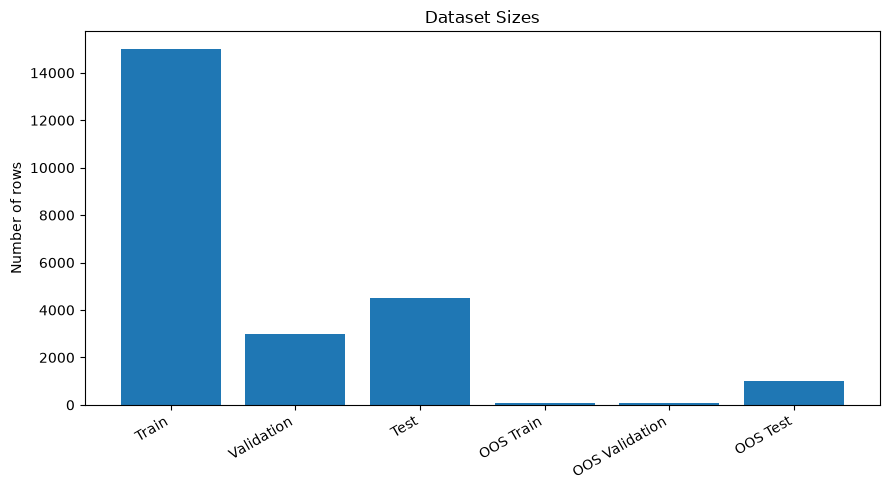

In [4]:
dfs = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df,
    "OOS Train": oos_train_df,
    "OOS Validation": oos_val_df,
    "OOS Test": oos_test_df,
}

plt.figure(figsize=(9, 5))
plt.bar(dfs.keys(), [len(df) for df in dfs.values()])
plt.ylabel("Number of rows")
plt.title("Dataset Sizes")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

From the chart, we can clearly see `oos Train` size is way smaller than Train itself so it makes sense to merge them together to simplify the training process.

In [5]:
train = pd.concat([train_df, oos_train_df], ignore_index=True)
test = pd.concat([test_df, oos_test_df], ignore_index=True)
val = pd.concat([val_df, oos_val_df], ignore_index=True)

## 2. EDA

### 1. Label Balance check

Using the description from UCI ML Repo, the dataset has a perfectly balanced amount of 100 samples per class across all 5 subdatasets. 

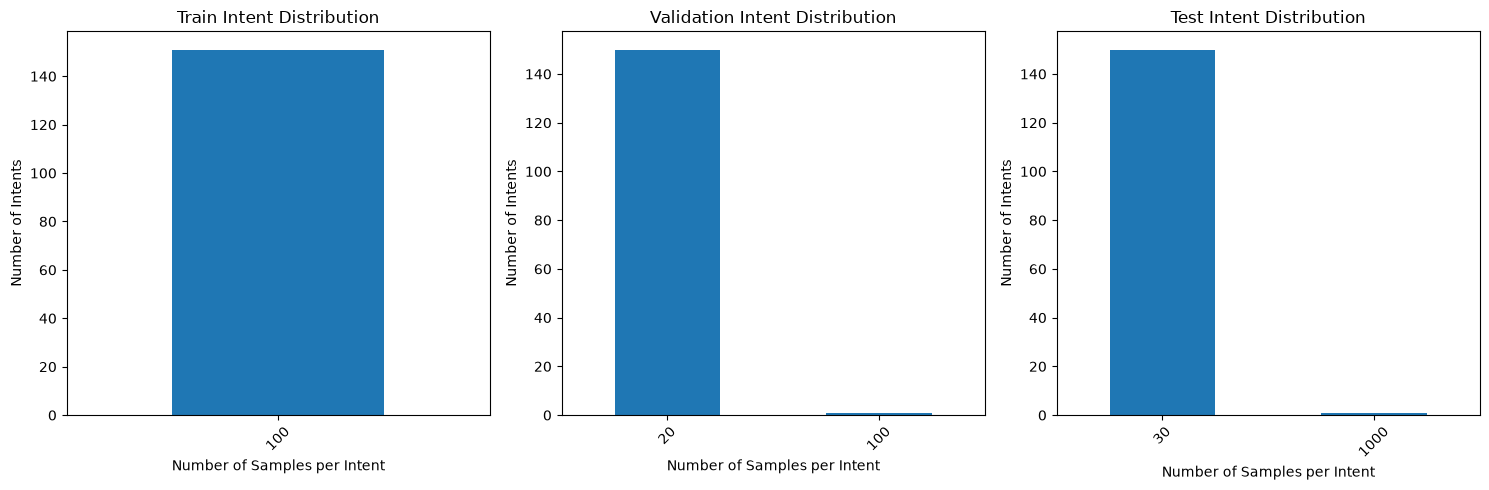

In [6]:
def plot_intent_distribution(df, title, ax):
    intent_counts = df["intent"].value_counts()
    size_distribution = intent_counts.value_counts().sort_index()

    size_distribution.plot(kind="bar", ax=ax)

    ax.set_title(title)
    ax.set_xlabel("Number of Samples per Intent")
    ax.set_ylabel("Number of Intents")
    ax.tick_params(axis="x", rotation=45)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

plot_intent_distribution(train, "Train Intent Distribution", axes[0])
plot_intent_distribution(val, "Validation Intent Distribution", axes[1])
plot_intent_distribution(test, "Test Intent Distribution", axes[2])

plt.tight_layout()
plt.show()

The data confirm the training set has balanced distribution. In the test set and validation set, the distribution of defined intent classes are perfectly balanced but the oos class seems to have a lot more samples. So, the computation of evaluation metrics like the confusion matrix should be investigated separatedly for oos intent.

### 2. Text length check across train data

I will investigate the length of the texts to see the distribution along the training dataset. From this point, the EDA will only be performed on train to explore the characteristic of the data. Test and evaluation will be reserved for training purpose only to test the generalization power of the model.

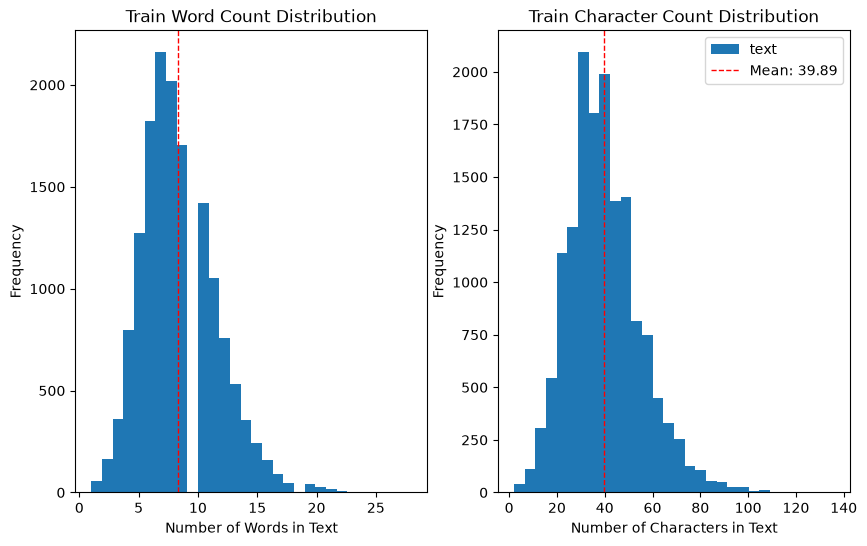

In [7]:
def word_count_distribution(df, title, ax):
    word_counts = df["text"].apply(lambda x: len(x.split()))
    word_counts.plot(kind="hist", bins=30, ax=ax)
    ax.axvline(
            word_counts.mean(),
            color="red",
            linestyle="--",
            linewidth=1,
            label=f"Mean: {word_counts.mean():.2f}"
        )
    ax.set_title(title)
    ax.set_xlabel("Number of Words in Text")
    ax.set_ylabel("Frequency")

def character_count_distribution(df, title, ax):
    char_counts = df["text"].apply(len)

    char_counts.plot(kind="hist", bins=30, ax=ax)

    ax.axvline(
        char_counts.mean(),
        color="red",
        linestyle="--",
        linewidth=1,
        label=f"Mean: {char_counts.mean():.2f}"
    )

    ax.set_title(title)
    ax.set_xlabel("Number of Characters in Text")
    ax.set_ylabel("Frequency")
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
word_count_distribution(train, "Train Word Count Distribution", axes[0])
character_count_distribution(train, "Train Character Count Distribution", axes[1])

The character count distribution is approximately bell-shaped and centered around its mean, suggesting that utterance lengths are relatively concentrated around a typical value. No substantial extreme values or unusual patterns were observed

## 3. Data Quality 

I will check the info() to identify NaN, duplications (conflict label if duplicated) and potential overlap across splits.

### a. Value Missingness

In [8]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 15100 entries, 0 to 15099
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    15100 non-null  str  
 1   intent  15100 non-null  str  
dtypes: str(2)
memory usage: 997.3 KB


This confirms no NaN features in the dataset.

### b. Duplications

In [9]:
len(train['text'].value_counts()[train['text'].value_counts() > 1])

0

There is no duplicated text in the training set.

In [10]:
tmp = pd.concat([train, test], ignore_index=True)
duplication_test =(len(tmp['text'].value_counts()[tmp['text'].value_counts() > 1]))
print(f"Proportion of duplicated texts in the combined train and test datasets: {duplication_test / len(train):.4f}")

tmp = pd.concat([train, val], ignore_index=True)
duplication_val =(len(tmp['text'].value_counts()[tmp['text'].value_counts() > 1]))
print(f"Proportion of duplicated texts in the combined train and validation datasets: {duplication_val / len(train):.4f}")

Proportion of duplicated texts in the combined train and test datasets: 0.0001
Proportion of duplicated texts in the combined train and validation datasets: 0.0002


The training and test sets shows a resonable amount of exact-duplicate overlap of 0.01%. Given its minimal magnitude, the original dataset partitions should be retained to preserve the benchmark evaluation.

## 2. Vocabulary Analysis

### a. Most frequent words

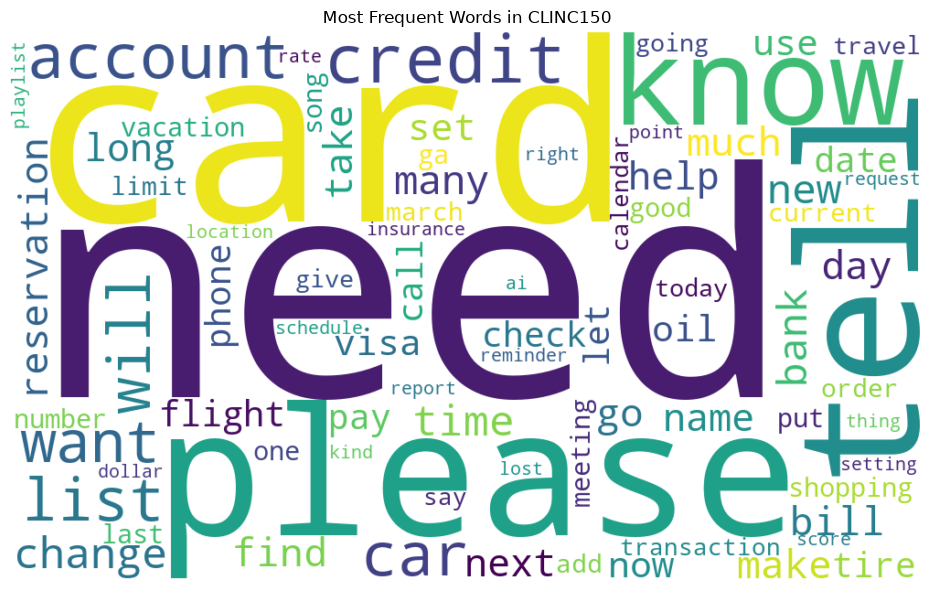

In [11]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

def plot_wordcloud(df, title, ax):
    text = " ".join(df["text"].dropna().astype(str))

    wordcloud = WordCloud(
        width=1000,
        height=600,
        background_color="white",
        stopwords=STOPWORDS,
        max_words=80,
        collocations=False
    ).generate(text)

    ax.imshow(wordcloud, interpolation="bilinear")
    ax.set_title(title)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(12, 6))

plot_wordcloud(train, "Most Frequent Words in CLINC150", ax)

plt.tight_layout()
plt.show()

Most of the words relate to finance like spending, tourism, or just for daily tasks. 

### 5. Semantic Analysis on intents

I use pretrained sentence-transformer model from HuggingFace to embed the labels (intents) and use cosine similarity of them. Then use t-SNE to visualize the clusters.

In [12]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

embeddings = model.encode(train["intent"].unique().tolist(), batch_size=32, show_progress_bar=True)


W1103 23:19:09.398000 49482 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

In [13]:
similarity_matrix = embeddings @ embeddings.T



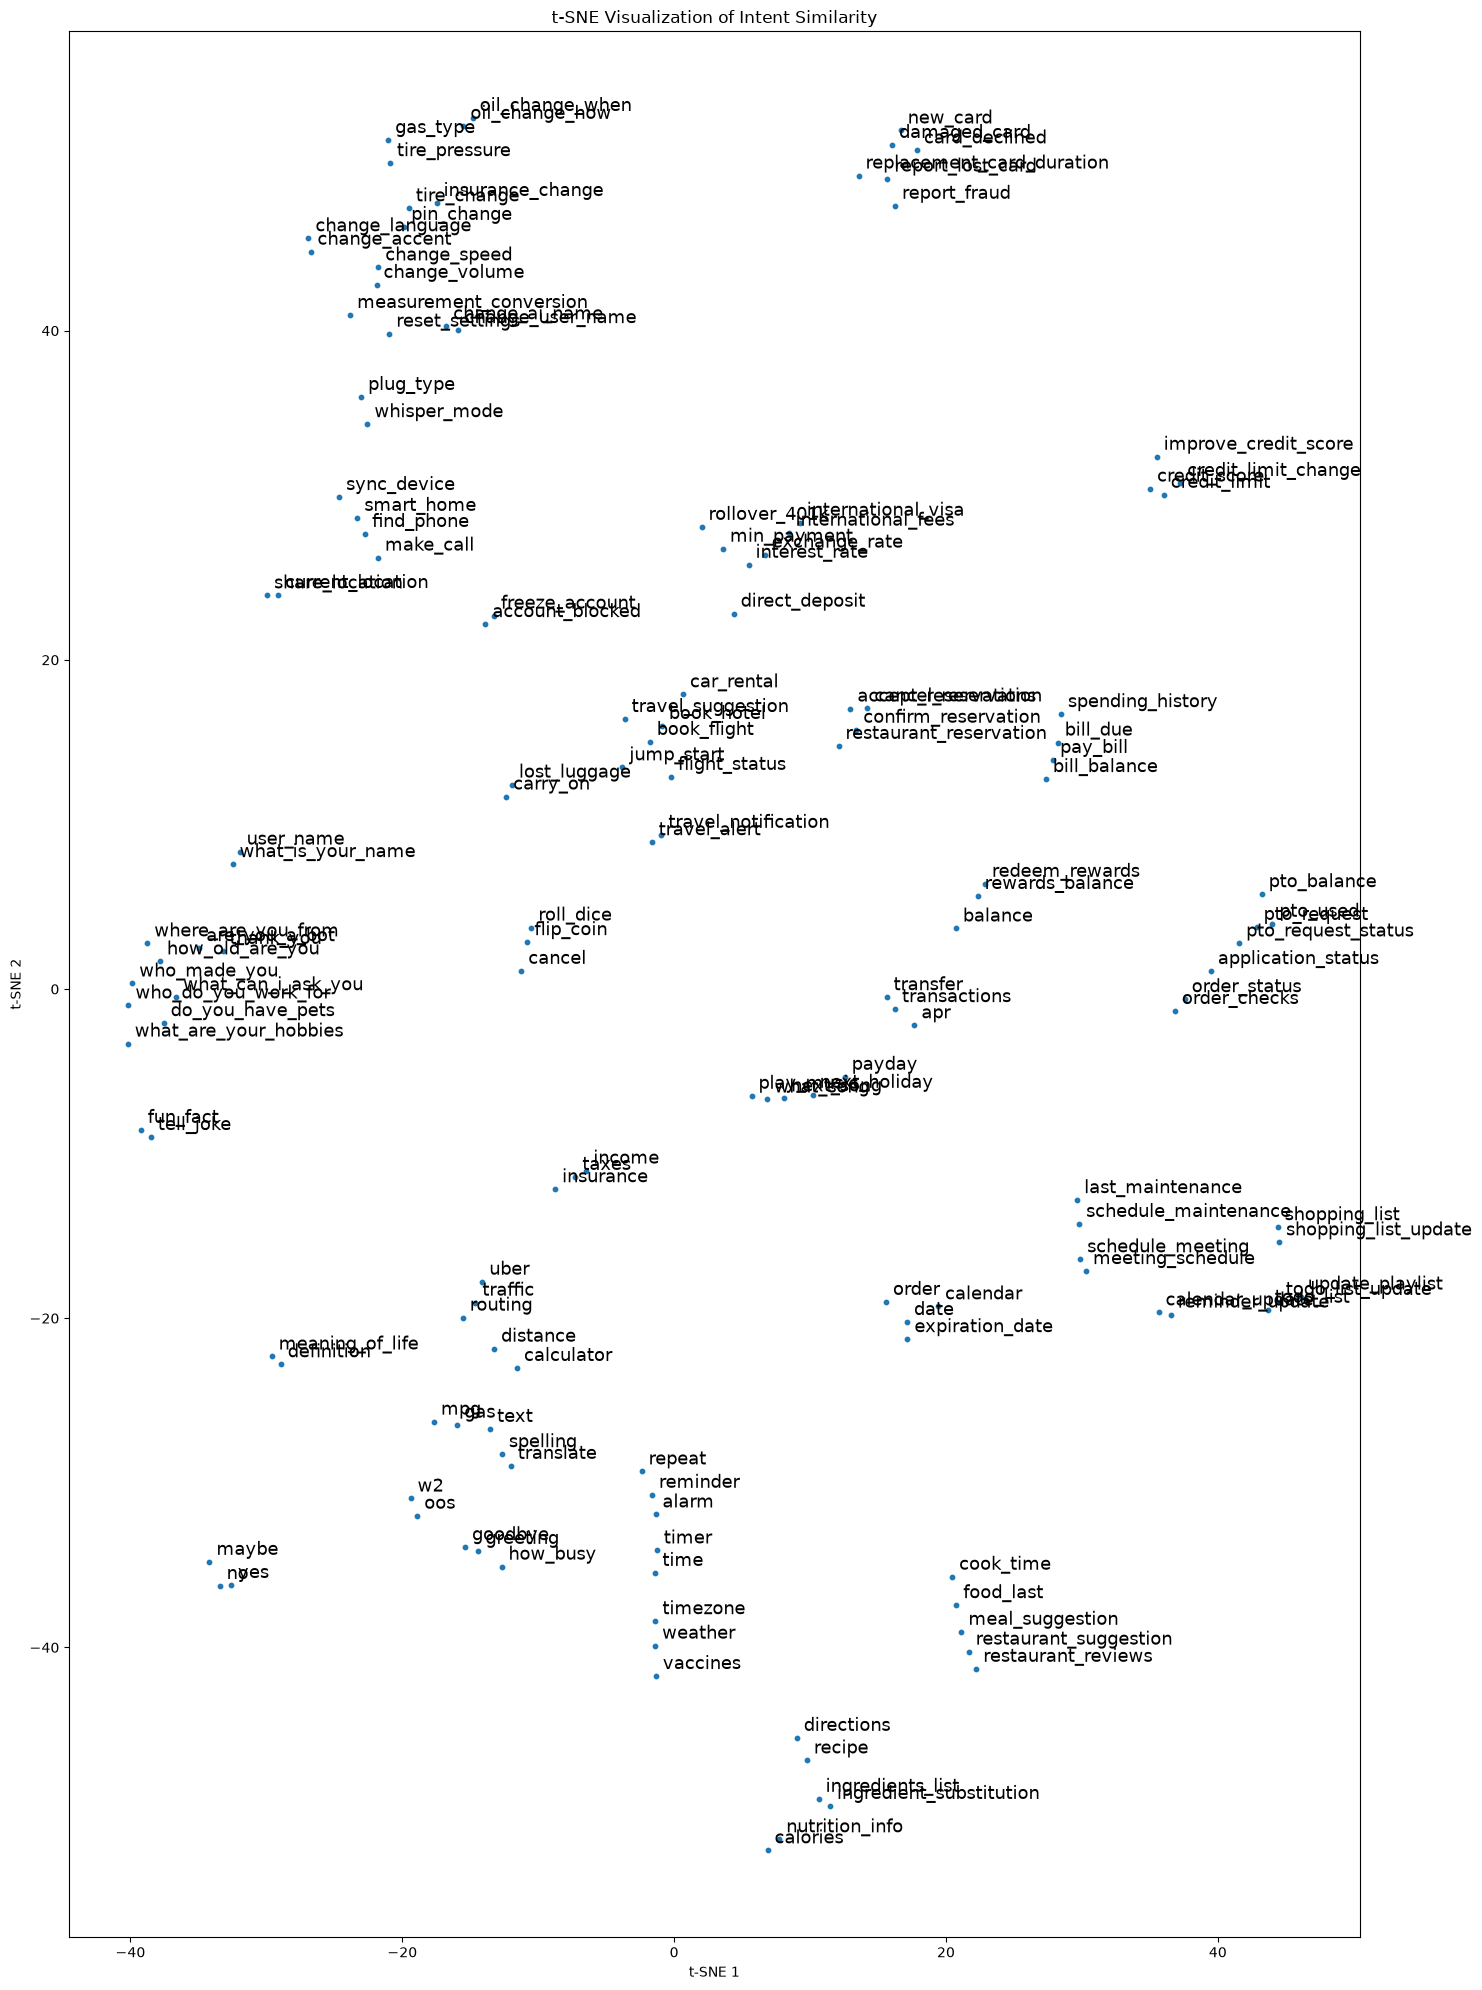

In [23]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, init="pca", learning_rate="auto", perplexity=3)

embedded = tsne.fit_transform(similarity_matrix)

labels = train["intent"].unique().tolist()
fig, ax = plt.subplots(figsize=(15, 20))
plt.scatter(embedded[:, 0], embedded[:, 1], s=10)

for i, label in enumerate(labels):
    plt.annotate(
        label,
        (embedded[i, 0], embedded[i, 1]),
        fontsize=13,
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("t-SNE Visualization of Intent Similarity")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

Looks cool hehe :) The t-SNE plot shows that many intents with similar meanings are grouped close together. For example, travel-related intents, financial intents, and food-related intents each form their own clusters. This suggests that the dataset has clear groups of related topics. However, some intents are very close to each other, which may make them harder for a model to tell apart during classification. Overall, the plot gives a useful overview of how the different intents are related.